In [1]:
# =============================================================================
#  SETUP — all imports, paths and shared constants for the whole notebook.
#  Every later cell assumes this has run. Run this first after a runtime restart.
# =============================================================================
!pip install opencv-python-headless scikit-image geopy requests -q

import os
import cv2
import numpy as np
import pandas as pd
import requests
import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPModel, CLIPProcessor
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/negotiated_modernism'
!mkdir -p {PROJECT_DIR}/images {PROJECT_DIR}/plans {PROJECT_DIR}/data

# The four case-study buildings that have exterior photos, floor plans and
# hand-marked window overlays. house1 (suburban control) has a photo only.
image_ids = ["savoye", "canoas", "freyhouse2", "kaufmann"]

# Pen colour used to hand-mark the windows on each *_marked image.
pen_colors = {"savoye": "red", "canoas": "red", "freyhouse2": "blue", "kaufmann": "red"}


Mounted at /content/drive


## 1 · Case studies and climate data

Building metadata plus long-term climate normals from the Open-Meteo archive.

In [2]:
buildings = pd.DataFrame([
    {"id": "savoye", "architect": "Le Corbusier", "building": "Villa Savoye",
     "city": "Poissy", "country": "France", "lat": 48.924, "lon": 2.028, "year": 1931},
    {"id": "canoas", "architect": "Niemeyer", "building": "Casa das Canoas",
     "city": "Rio de Janeiro", "country": "Brazil", "lat": -22.99, "lon": -43.28, "year": 1953},
    {"id": "freyhouse2", "architect": "Frey", "building": "Frey House II",
     "city": "Palm Springs", "country": "USA", "lat": 33.83, "lon": -116.54, "year": 1964},
    {"id": "kaufmann", "architect": "Neutra", "building": "Kaufmann Desert House",
     "city": "Palm Springs", "country": "USA", "lat": 33.82, "lon": -116.54, "year": 1946},
])
buildings.to_csv(f"{PROJECT_DIR}/data/buildings.csv", index=False)
buildings


,id,architect,building,city,country,lat,lon,year
0,savoye,Le Corbusier,Villa Savoye,Poissy,France,48.924,2.028,1931
1,canoas,Niemeyer,Casa das Canoas,Rio de Janeiro,Brazil,-22.990,-43.280,1953
2,freyhouse2,Frey,Frey House II,Palm Springs,USA,33.830,-116.540,1964
3,kaufmann,Neutra,Kaufmann Desert House,Palm Springs,USA,33.820,-116.540,1946


In [3]:
buildings = pd.read_csv(f"{PROJECT_DIR}/data/buildings.csv")

def get_climate(lat, lon):
    """Pull long-term daily normals from Open-Meteo Archive API (2015-2024 avg)."""
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2015-01-01",
        "end_date": "2024-12-31",
        "daily": "temperature_2m_mean,shortwave_radiation_sum,sunshine_duration",
        "timezone": "auto"
    }
    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    daily = r.json()["daily"]
    df = pd.DataFrame(daily)
    return {
        "avg_temp_c": df["temperature_2m_mean"].mean(),
        "avg_solar_radiation_MJm2": df["shortwave_radiation_sum"].mean(),
        "avg_sunshine_hours_per_day": df["sunshine_duration"].mean() / 3600
    }

climate_rows = []
for _, row in buildings.iterrows():
    print(f"Fetching climate for {row['building']} ({row['city']})...")
    data = get_climate(row["lat"], row["lon"])
    data["id"] = row["id"]
    climate_rows.append(data)

climate_df = pd.DataFrame(climate_rows)
buildings = buildings.merge(climate_df, on="id")
buildings.to_csv(f"{PROJECT_DIR}/data/buildings.csv", index=False)
buildings


Fetching climate for Villa Savoye (Poissy)...
Fetching climate for Casa das Canoas (Rio de Janeiro)...
Fetching climate for Frey House II (Palm Springs)...
Fetching climate for Kaufmann Desert House (Palm Springs)...


,id,architect,building,city,country,lat,lon,year,avg_temp_c,avg_solar_radiation_MJm2,avg_sunshine_hours_per_day
0,savoye,Le Corbusier,Villa Savoye,Poissy,France,48.924,2.028,1931,12.057733,12.041341,7.882144
1,canoas,Niemeyer,Casa das Canoas,Rio de Janeiro,Brazil,-22.990,-43.280,1953,20.801506,18.119699,9.611715
2,freyhouse2,Frey,Frey House II,Palm Springs,USA,33.830,-116.540,1964,23.869477,21.097123,11.299906
3,kaufmann,Neutra,Kaufmann Desert House,Palm Springs,USA,33.820,-116.540,1946,23.947523,21.097123,11.299906


## 2 · Exterior photographs

Load, standardise and inspect the exterior crops.

savoye: shape=(600, 1200, 3)
canoas: shape=(691, 1024, 3)
freyhouse2: shape=(2058, 3088, 3)
kaufmann: shape=(639, 1000, 3)


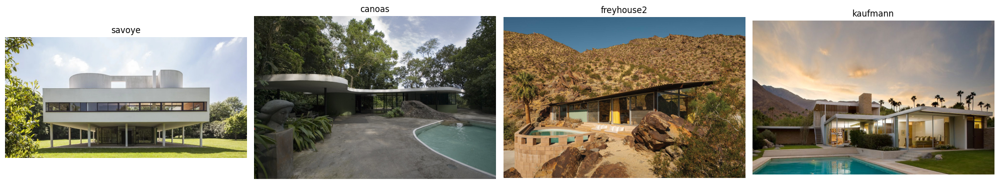

In [4]:
def load_and_inspect(image_id, folder="images", ext="jpg"):
    path = f"{PROJECT_DIR}/{folder}/{image_id}.{ext}"
    img = cv2.imread(path)
    if img is None:
        print(f"⚠️ Could not load {path} — check filename/extension")
        return None
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    print(f"{image_id}: shape={img.shape}")
    return img_rgb

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
raw_images = {}
for ax, img_id in zip(axes, image_ids):
    img = load_and_inspect(img_id)
    raw_images[img_id] = img
    if img is not None:
        ax.imshow(img)
        ax.set_title(img_id)
        ax.axis('off')
plt.tight_layout()
plt.show()


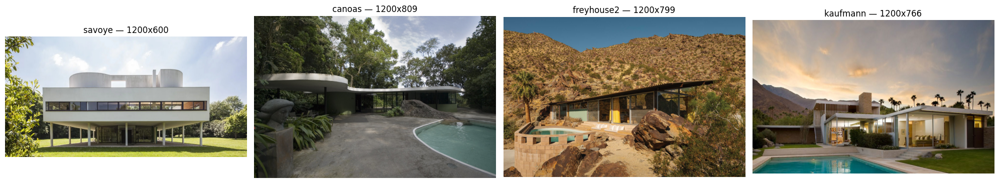

In [5]:
TARGET_WIDTH = 1200  # common working resolution

def standardize(image_id, folder="images", ext="jpg", target_width=TARGET_WIDTH):
    path = f"{PROJECT_DIR}/{folder}/{image_id}.{ext}"
    img = cv2.imread(path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img_rgb.shape[:2]
    scale = target_width / w
    new_h = int(h * scale)
    resized = cv2.resize(img_rgb, (target_width, new_h), interpolation=cv2.INTER_AREA)

    out_path = f"{PROJECT_DIR}/images/{image_id}_std.jpg"
    cv2.imwrite(out_path, cv2.cvtColor(resized, cv2.COLOR_RGB2BGR))
    return resized

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
standardized = {}
for ax, img_id in zip(axes, image_ids):
    std_img = standardize(img_id)
    standardized[img_id] = std_img
    ax.imshow(std_img)
    ax.set_title(f"{img_id} — {std_img.shape[1]}x{std_img.shape[0]}")
    ax.axis('off')
plt.tight_layout()
plt.show()


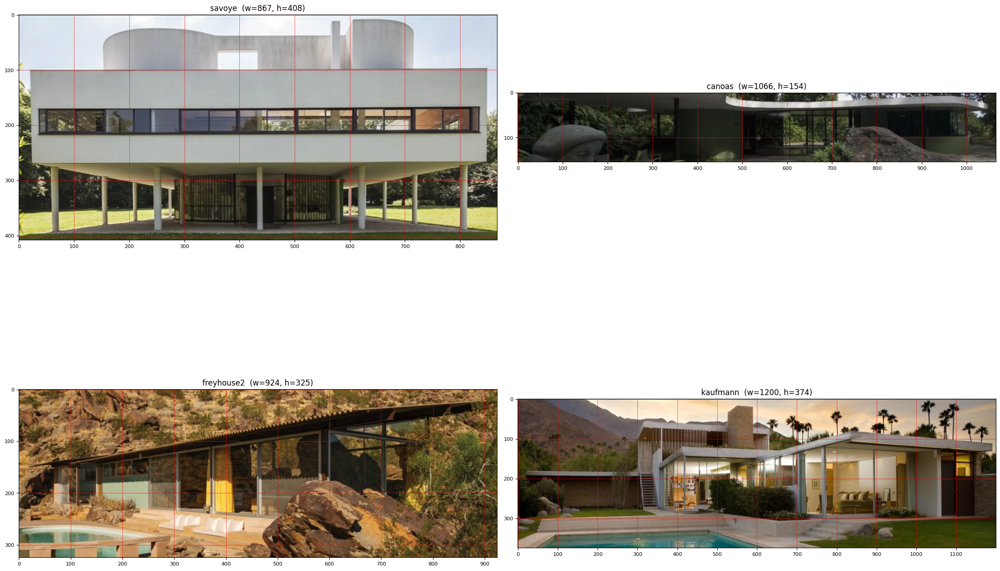

In [6]:
def show_all_with_grids(image_ids, grid_step=100):
    fig, axes = plt.subplots(2, 2, figsize=(22, 18))
    axes = axes.flatten()

    for ax, image_id in zip(axes, image_ids):
        path = f"{PROJECT_DIR}/images/{image_id}_crop.jpg"
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        ax.imshow(img)
        ax.set_xticks(np.arange(0, w, grid_step))
        ax.set_yticks(np.arange(0, h, grid_step))
        ax.tick_params(labelsize=8)
        ax.grid(color='red', linewidth=0.6, alpha=0.7)
        ax.set_title(f"{image_id}  (w={w}, h={h})", fontsize=12)

    plt.tight_layout()
    plt.show()

show_all_with_grids(image_ids)


In [7]:
print(os.listdir(f"{PROJECT_DIR}/images"))


['freyhouse2.jpg', 'kaufmann.jpg', 'savoye.jpg', 'savoye_crop.jpg', 'kaufmann_crop.jpg', 'freyhouse2_crop.jpg', 'canoas.jpg', 'canoas_crop.jpg', 'canoas_marked.jpg', 'kaufmann_marked.jpg', 'savoye_marked.jpg', 'freyhouse2_marked.jpg', 'house.jpeg', 'house_crop.jpeg', 'house1_crop.jpeg', 'freyhouse2_std.jpg', 'savoye_std.jpg', 'canoas_std.jpg', 'kaufmann_std.jpg', 'savoye_angle2.jpg', 'canoas_angle2.jpg', 'freyhouse_angle2.jpg', 'kaufmann_angle2.jpg', 'notflat2.jpg', 'notflat1.jpg', 'gamblehouse_angle2.jpg', 'gamblehouse.jpg']


## 3 · Glazing ratio (hand-marked windows)

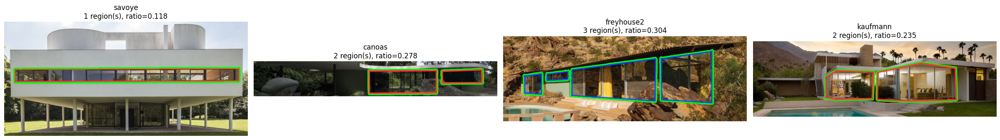


Glazing ratios:
  savoye: 0.118
  canoas: 0.278
  freyhouse2: 0.304
  kaufmann: 0.235


In [8]:
def detect_marks(image_id, pen_color="red", folder="images"):
    # find_marked_path handles jpg/jpeg/png; the old hardcoded ".jpg" gave a
    # confusing cvtColor crash when the file had any other extension.
    path = None
    for _ext in ("jpg", "jpeg", "png", "JPG", "JPEG", "PNG"):
        _p = f"{PROJECT_DIR}/{folder}/{image_id}_marked.{_ext}"
        if os.path.exists(_p):
            path = _p
            break
    if path is None:
        raise FileNotFoundError(f"No marked image for {image_id} in {folder}/")
    img = cv2.imread(path)
    if img is None:
        raise IOError(f"cv2 could not decode {path}")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    if pen_color == "red":
        mask = (cv2.inRange(hsv, np.array([0,100,100]), np.array([10,255,255])) |
                cv2.inRange(hsv, np.array([160,100,100]), np.array([180,255,255])))
    elif pen_color == "blue":
        mask = cv2.inRange(hsv, np.array([100,100,100]), np.array([130,255,255]))
    else:
        raise ValueError(f"Unsupported pen_color {pen_color!r} (use 'red' or 'blue')")

    kernel = np.ones((5, 5), np.uint8)
    closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)

    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # A fixed 500 px cut-off means a different real-world size on every photo
    # (0.11% of the kaufmann image but 0.30% of canoas). Scale it instead.
    img_area = img.shape[0] * img.shape[1]
    contours = [c for c in contours if cv2.contourArea(c) > 0.0005 * img_area]

    total_glazing_area = sum(cv2.contourArea(c) for c in contours)

    # ratio            : glass / whole photo. Depends on how much sky and lawn
    #                    the crop happens to include, so it is NOT comparable
    #                    across buildings. Kept for continuity with earlier runs.
    # ratio_facade     : glass / bounding box of the annotated window band.
    #                    Crop-independent. Caveat: with a single drawn region it
    #                    degenerates towards "how rectangular is that region".
    ratio = total_glazing_area / img_area
    if contours:
        _b = [cv2.boundingRect(c) for c in contours]
        _x0, _y0 = min(v[0] for v in _b), min(v[1] for v in _b)
        _x1 = max(v[0] + v[2] for v in _b)
        _y1 = max(v[1] + v[3] for v in _b)
        _facade = max(1, (_x1 - _x0) * (_y1 - _y0))
    else:
        _facade = img_area
    ratio_facade = total_glazing_area / _facade

    vis = img_rgb.copy()
    cv2.drawContours(vis, contours, -1, (0, 255, 0), 4)
    return ratio, contours, vis, ratio_facade

results = {}
results_facade = {}
fig, axes = plt.subplots(1, 4, figsize=(24, 7))

for ax, image_id in zip(axes, image_ids):
    ratio, contours, vis, ratio_facade = detect_marks(image_id, pen_color=pen_colors[image_id])
    results[image_id] = ratio
    results_facade[image_id] = ratio_facade
    ax.imshow(vis)
    ax.set_title(f"{image_id}\n{len(contours)} region(s), ratio={ratio:.3f}", fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.show()

print("\nGlazing ratios (per photo / per annotated facade):")
for image_id, ratio in results.items():
    print(f"  {image_id}: {ratio:.3f}  /  {results_facade[image_id]:.3f}")


In [9]:
buildings = pd.read_csv(f"{PROJECT_DIR}/data/buildings.csv")

glazing_ratio_map = results  # from the previous cell: {"savoye": 0.118, "canoas": 0.298, ...}

buildings["id"] = buildings["id"].astype(str)
buildings["glazing_ratio"] = buildings["id"].map(glazing_ratio_map)

buildings.to_csv(f"{PROJECT_DIR}/data/buildings.csv", index=False)
buildings


,id,architect,building,city,country,lat,lon,year,avg_temp_c,avg_solar_radiation_MJm2,avg_sunshine_hours_per_day,glazing_ratio
0,savoye,Le Corbusier,Villa Savoye,Poissy,France,48.924,2.028,1931,12.057733,12.041341,7.882144,0.117740
1,canoas,Niemeyer,Casa das Canoas,Rio de Janeiro,Brazil,-22.990,-43.280,1953,20.801506,18.119699,9.611715,0.277728
2,freyhouse2,Frey,Frey House II,Palm Springs,USA,33.830,-116.540,1964,23.869477,21.097123,11.299906,0.304194
3,kaufmann,Neutra,Kaufmann Desert House,Palm Springs,USA,33.820,-116.540,1946,23.947523,21.097123,11.299906,0.235012


## 4 · Pilotis / column detection

In [11]:
def detect_columns_hough(image_id, band_top_frac=0.0, band_bottom_frac=1.0, folder="images",
                          min_length_frac=0.1, angle_tolerance=10):
    """Count vertical supports in a horizontal band of the facade.

    The band is given as a FRACTION of image height. It used to be absolute
    pixels, which silently broke on differently-sized crops: band_top_y=145 on
    canoas_crop (154 px tall) left a 9 px strip of lawn below the building.
    """
    path = f"{PROJECT_DIR}/{folder}/{image_id}_crop.jpg"
    img = cv2.imread(path)
    if img is None:
        print(f"ERROR: Could not read image at {path}")
        return 0, []

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape

    y1, y2 = max(0, int(band_top_frac * h)), min(h, int(band_bottom_frac * h))
    if y2 <= y1:
        print("Warning: Invalid band range (top >= bottom)")
        return 0, []
    if (y2 - y1) < 0.10 * h:
        print(f"Warning: {image_id} band is only {y2-y1}px ({(y2-y1)/h:.0%} of the image) "
              f"- too thin to contain a storey; columns will be missed.")

    band = gray[y1:y2, :]
    band_h = y2 - y1

    edges = cv2.Canny(band, 50, 150)
    min_len = int(band_h * min_length_frac)
    lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=30,
                             minLineLength=min_len, maxLineGap=10)

    vertical_xs = []
    if lines is not None:
        for line in lines:
            # --- THE CRITICAL FIX ---
            # Flatten the line to a 1D array of 4 integers regardless of OpenCV version
            lx1, ly1, lx2, ly2 = line.reshape(4)

            angle = np.degrees(np.arctan2(ly2 - ly1, lx2 - lx1))
            # Check if the line is vertical
            if abs(abs(angle) - 90) < angle_tolerance:
                vertical_xs.append((lx1 + lx2) / 2)

    # Group columns that are very close to each other
    vertical_xs.sort()
    merged, merge_dist = [], w * 0.02
    for x in vertical_xs:
        if merged and x - merged[-1][-1] < merge_dist:
            merged[-1].append(x)
        else:
            merged.append([x])
    column_positions = [np.mean(g) for g in merged]

    # Estimate void ratio (occupancy)
    est_col_width = max(int(w * 0.015), 5)
    solid_px = min(len(column_positions) * est_col_width, w)
    # A colonnade is what makes the ground plane open. With no columns found
    # there is no colonnade, so openness is 0 - not 1. The old formula returned
    # 1.00 whenever detection failed, scoring a solid wall as MORE open than
    # Savoye's eight real pilotis (0.88).
    void_ratio = 0.0 if len(column_positions) == 0 else 1 - solid_px / w

    # Visualization
    vis = img_rgb.copy()
    cv2.rectangle(vis, (0, y1), (w, y2), (255, 255, 0), 3) # Yellow box shows the analysis zone
    for cx in column_positions:
        cv2.line(vis, (int(cx), y1), (int(cx), y2), (255, 0, 0), 3) # Red lines show detected columns

    plt.figure(figsize=(12, 8))
    plt.imshow(vis)
    plt.title(f"{image_id}: {len(column_positions)} columns, void_ratio={void_ratio:.2f} (Y-range: {y1}-{y2})")
    plt.axis('off')
    plt.show()
    return void_ratio, column_positions


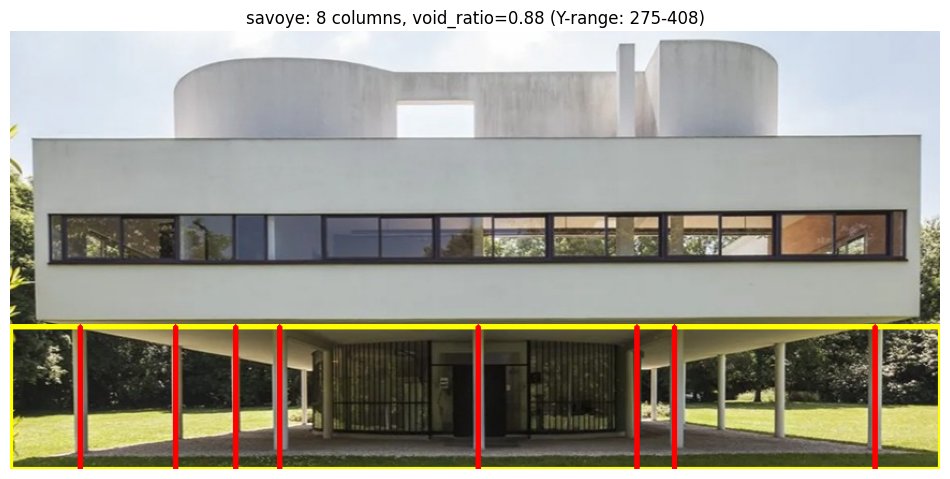

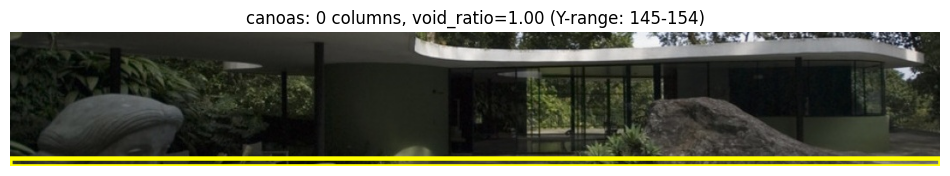

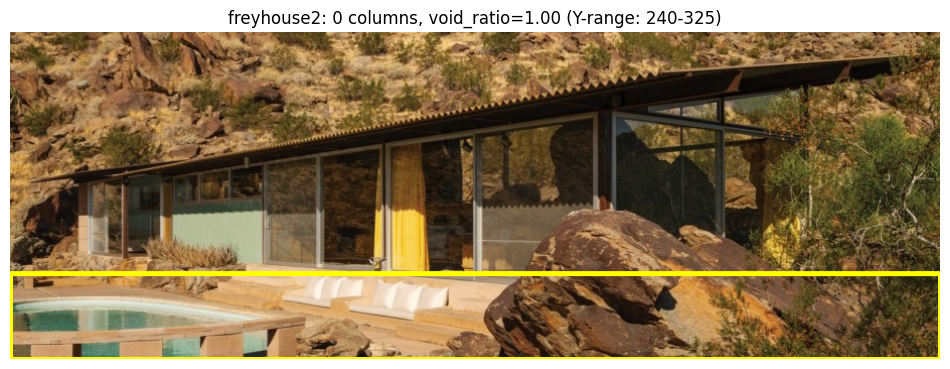

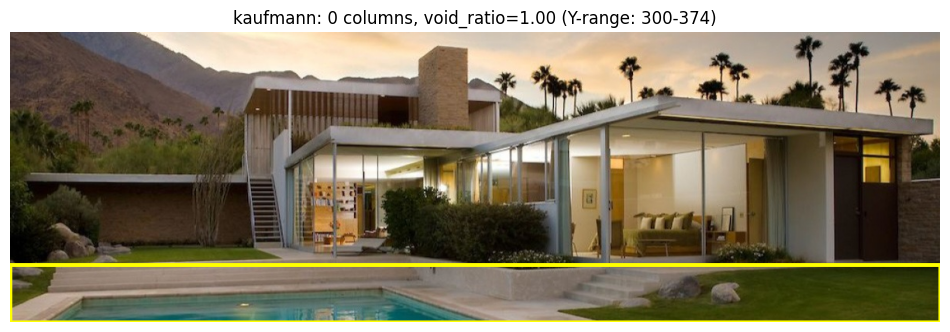

In [12]:
# Bands as fractions of image height (same regions as the previous pixel values).
# Only savoye's band actually covers a ground storey; the other three sit over
# terrace/pool/lawn, which is why they report no columns. That happens to match
# the architecture - only Savoye is raised on true pilotis - but the detector is
# validated on Savoye alone, so do not read the zeros as measurements.
void_ratio, columns = detect_columns_hough("savoye",     band_top_frac=0.674)
void_ratio, columns = detect_columns_hough("canoas",     band_top_frac=0.942)
void_ratio, columns = detect_columns_hough("freyhouse2", band_top_frac=0.738)
void_ratio, columns = detect_columns_hough("kaufmann",   band_top_frac=0.802)


## 5 · Floor plans → open-plan metrics

In [13]:
plans_path = f"{PROJECT_DIR}/plans"

if os.path.exists(plans_path):
    print("Files in plans/:")
    for f in sorted(os.listdir(plans_path)):
        print(" -", f)
else:
    print("plans/ folder doesn't exist yet or is empty")


Files in plans/:
 - canoas.jpg
 - canoas_marked.jpg
 - freyhouse2.jpeg
 - freyhouse2_marked.jpeg
 - kaufmann.jpg
 - kaufmann_marked.jpg
 - rotonda.jpg
 - rotonda_marked.jpg
 - savoye.jpg
 - savoye_marked.jpg


In [14]:
def find_plan_path(building_id, folder="plans"):
    for ext in ["jpg", "jpeg", "JPG", "JPEG"]:
        path = f"{PROJECT_DIR}/{folder}/{building_id}.{ext}"
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"No plan file found for {building_id} with jpg/jpeg extensions")

# quick check across all 4
plan_ids = ["savoye", "canoas", "freyhouse2", "kaufmann", "rotonda"]
for pid in plan_ids:
    try:
        path = find_plan_path(pid)
        print(f"{pid}: found at {path}")
    except FileNotFoundError as e:
        print(f"{pid}: {e}")


savoye: found at /content/drive/MyDrive/negotiated_modernism/plans/savoye.jpg
canoas: found at /content/drive/MyDrive/negotiated_modernism/plans/canoas.jpg
freyhouse2: found at /content/drive/MyDrive/negotiated_modernism/plans/freyhouse2.jpeg
kaufmann: found at /content/drive/MyDrive/negotiated_modernism/plans/kaufmann.jpg
rotonda: found at /content/drive/MyDrive/negotiated_modernism/plans/rotonda.jpg


In [16]:
# 2. Helper to find the marked plan
def find_marked_plan_path(building_id, folder="plans"):
    for ext in ["jpg", "jpeg", "JPG", "JPEG"]:
        path = f"{PROJECT_DIR}/{folder}/{building_id}_marked.{ext}"
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"No marked plan found for {building_id}")

# --- FIXED V6 WITH DIMENSION SAFETY CHECK ---
def adaptive_room_flood_v6(building_id, min_area_ratio=0.005):
    # 1. Load both the base plan and the marked plan
    path_plan = find_plan_path(building_id)
    path_marked = find_marked_plan_path(building_id)

    img_base = cv2.imread(path_plan)
    img_marked = cv2.imread(path_marked)

    # --- CRITICAL FIX: FORCE DIMENSIONS TO MATCH ---
    if img_base.shape[:2] != img_marked.shape[:2]:
        h, w = img_base.shape[:2]
        img_marked = cv2.resize(img_marked, (w, h), interpolation=cv2.INTER_NEAREST)
    # ------------------------------------------------

    # Explicitly use the MARKED image for the visualization background
    img_marked_rgb = cv2.cvtColor(img_marked, cv2.COLOR_BGR2RGB)

    h, w = img_base.shape[:2]
    diagonal = np.sqrt(h**2 + w**2)

    # --- ADAPTIVE PARAMETERS ---
    # NOTE: this evaluates to 1x1 (a no-op) on every plan except freyhouse2.
    # That is deliberate now: forcing a real 3x3 kernel over-erodes the thin
    # walls of these small scans - savoye collapses from 11 rooms to 1 and
    # rotonda flips to "open plan". Left as-is; normalise plan resolution first
    # if you ever want a genuinely adaptive kernel here.
    thickness_kernel_size = max(1, int(diagonal * 0.0015))
    bridge_radius_px = max(1, int(diagonal * 0.015))

    # --- STEP 1: EXTRACT INTERIOR WALLS (FROM BASE IMAGE) ---
    gray = cv2.cvtColor(img_base, cv2.COLOR_BGR2GRAY)
    # NOTE: a fixed 128 cut-off is crude, but Otsu was tested and flips canoas
    # to "not open plan" - these plans are line drawings, not photos, so the
    # bimodal assumption Otsu relies on does not hold. Left as-is.
    _, binary = cv2.threshold(gray, 128, 255, cv2.THRESH_BINARY_INV)
    kernel_thick = np.ones((thickness_kernel_size, thickness_kernel_size), np.uint8)
    interior_walls = cv2.erode(binary, kernel_thick, iterations=1)
    interior_walls = cv2.dilate(interior_walls, kernel_thick, iterations=1)

    # --- STEP 2: EXTRACT GREEN ENVELOPE (FROM MARKED IMAGE) ---
    hsv = cv2.cvtColor(img_marked, cv2.COLOR_BGR2HSV)
    lower_green = np.array([40, 80, 80])
    upper_green = np.array([80, 255, 255])
    green_mask = cv2.inRange(hsv, lower_green, upper_green)

    # Close the green mask to ensure corners connect mathematically
    closing_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (int(diagonal * 0.02) + 1, int(diagonal * 0.02) + 1))
    closed_green_mask = cv2.morphologyEx(green_mask, cv2.MORPH_CLOSE, closing_kernel)

    contours, _ = cv2.findContours(closed_green_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    envelope_mask = np.zeros(green_mask.shape, dtype=np.uint8)
    inside_mask = np.zeros(green_mask.shape, dtype=np.uint8)

    if contours:
        largest = max(contours, key=cv2.contourArea)

        # Create a thick green barrier wall for flood fill to stop at
        cv2.drawContours(envelope_mask, [largest], -1, 255, thickness=int(diagonal * 0.015))
        barrier_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (int(diagonal*0.02)+1, int(diagonal*0.02)+1))
        envelope_mask = cv2.dilate(envelope_mask, barrier_kernel, iterations=1)

        # Strictly fill the INSIDE of the closed polygon (Prevents outside coloring)
        cv2.drawContours(inside_mask, [largest], -1, 255, thickness=-1)

    if envelope_mask.shape != interior_walls.shape:
        envelope_mask = cv2.resize(envelope_mask, (interior_walls.shape[1], interior_walls.shape[0]), interpolation=cv2.INTER_NEAREST)
        inside_mask = cv2.resize(inside_mask, (interior_walls.shape[1], interior_walls.shape[0]), interpolation=cv2.INTER_NEAREST)

    # --- STEP 3: CLOSE INTERIOR WALLS ---
    kernel_bridge = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (bridge_radius_px*2+1, bridge_radius_px*2+1))
    closed_interior_walls = cv2.morphologyEx(interior_walls, cv2.MORPH_CLOSE, kernel_bridge)

    # --- STEP 4: COMBINE BARRIERS ---
    combined_walls = cv2.bitwise_or(closed_interior_walls, envelope_mask)
    space_mask = cv2.bitwise_not(combined_walls) # 0=walls, 255=empty space

    # --- STEP 5: CONNECTED COMPONENTS (ROOM SEGMENTATION) ---
    n_components, labels, stats, _ = cv2.connectedComponentsWithStats(space_mask, connectivity=8)

    background_labels = set()
    for x, y in [(0, 0), (0, h-1), (w-1, 0), (w-1, h-1)]:
        background_labels.add(labels[y, x])

    # Seeded so figures are reproducible run to run (they used to be random).
    _room_palette = np.random.RandomState(0)
    overlay = img_marked_rgb.copy() # Uses the marked image as the canvas!
    min_area = space_mask.size * min_area_ratio
    room_blobs = {}
    n_rooms = 0

    for i in range(1, n_components):
        area = stats[i, cv2.CC_STAT_AREA]

        if i in background_labels or area < min_area:
            continue

        mask = labels == i

        # Restrict coloring to the INSIDE of the green boundary
        mask = mask & (inside_mask == 255)

        if np.sum(mask) < (min_area * 0.1):
            continue

        color = _room_palette.randint(50, 255, 3)
        # Since dimensions are forced to match, this will never error now.
        overlay[mask] = overlay[mask] * 0.5 + color * 0.5

        room_blobs[f"room_{i}"] = {
            "bbox": (stats[i, cv2.CC_STAT_LEFT], stats[i, cv2.CC_STAT_TOP],
                     stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]),
            "mask": mask,
            # area must match `mask`, which was cropped to inside the envelope.
            # Storing the uncropped stats[] area let every downstream metric mix
            # two different regions. Identical on these five plans, wrong the
            # moment a room straddles the envelope.
            "area": int(np.sum(mask)),
            "area_uncropped": int(area)
        }
        n_rooms += 1

    plt.figure(figsize=(9,9))
    plt.imshow(overlay.astype(np.uint8))
    plt.title(f"{building_id} @ adaptive radius={bridge_radius_px}px, min_area={min_area_ratio*100:.2f}% — {n_rooms} rooms")
    plt.axis('off')
    plt.show()

    return overlay, room_blobs, space_mask, labels, inside_mask, closed_interior_walls


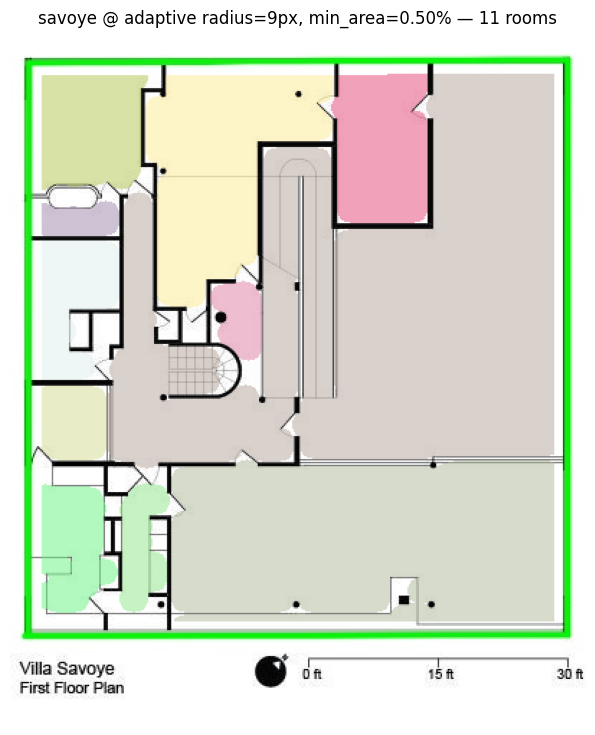

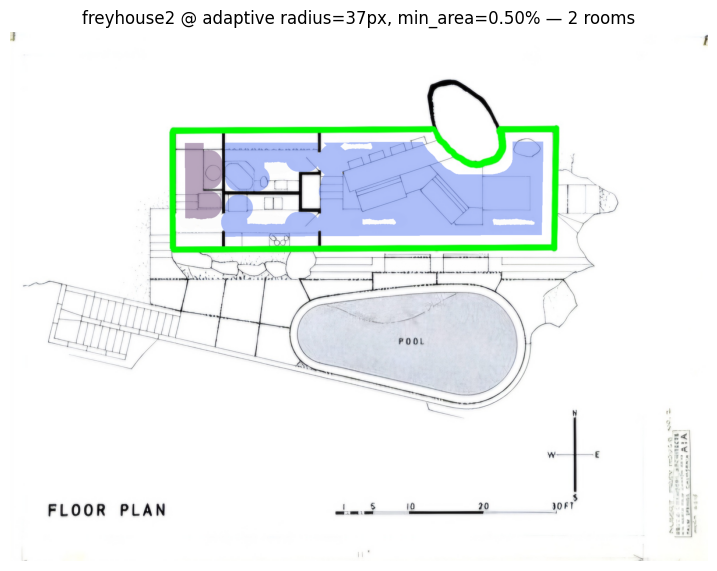

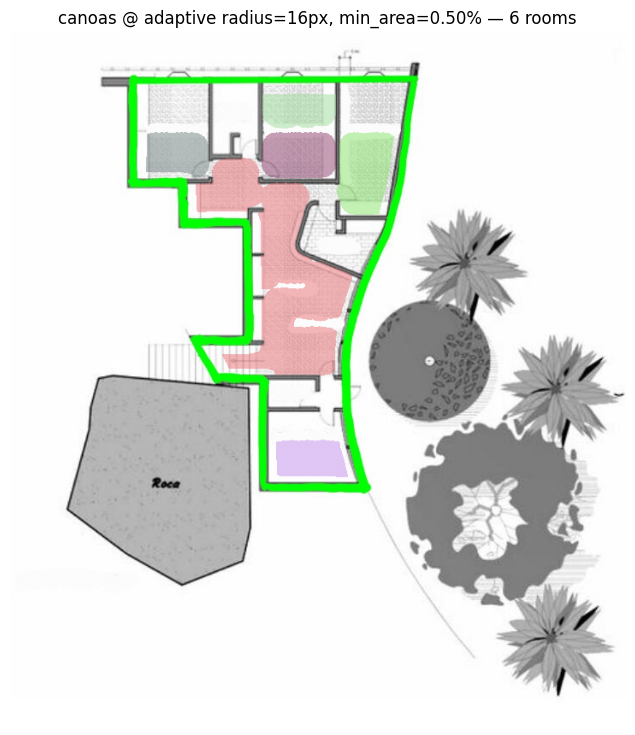

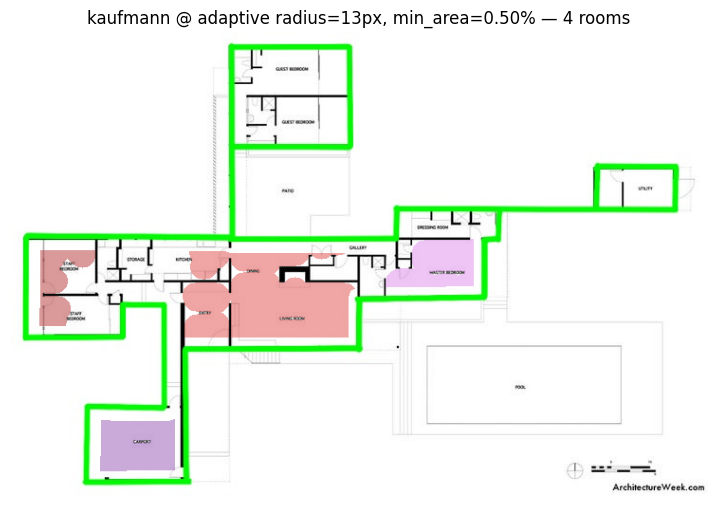

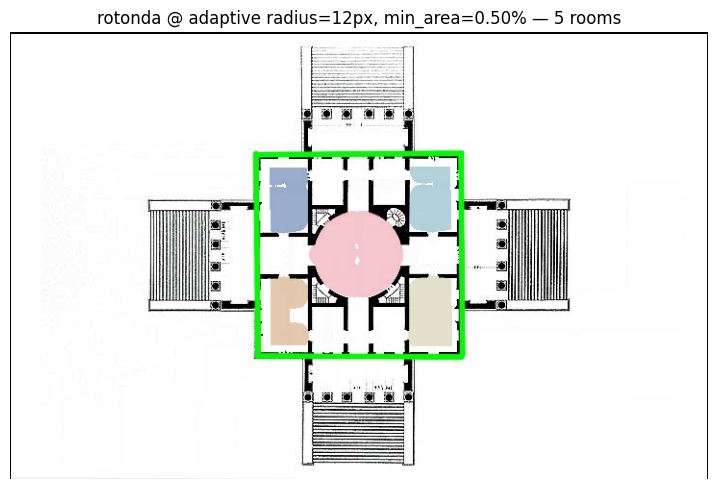

In [17]:
overlay, room_blobs, space_mask, labels, inside_mask, closed_interior_walls = adaptive_room_flood_v6("savoye")
overlay, room_blobs, space_mask, labels, inside_mask, closed_interior_walls = adaptive_room_flood_v6("freyhouse2")
overlay, room_blobs, space_mask, labels, inside_mask, closed_interior_walls = adaptive_room_flood_v6("canoas")
overlay, room_blobs, space_mask, labels, inside_mask, closed_interior_walls = adaptive_room_flood_v6("kaufmann")
overlay, room_blobs, space_mask, labels, inside_mask, closed_interior_walls = adaptive_room_flood_v6("rotonda")


In [18]:
def analyze_open_plan_metrics_v11(room_blobs, inside_mask, closed_interior_walls):
    total_interior_area = np.sum(inside_mask == 255)
    if total_interior_area == 0:
        return {"is_open_plan": False, "final_score": 0}

    if len(room_blobs) == 0:
        return {"is_open_plan": False, "final_score": 0}

    # 1. Find the largest room
    largest_room = max(room_blobs.values(), key=lambda x: x['area'])
    max_area = largest_room['area']

    # 2. Calculate Geometry Metrics
    # Rule 1: Area Ratio (Does the largest room physically dominate?)
    blob_ratio = max_area / total_interior_area

    # Rule 2: Internal Wall Density.
    # The old version asked how many WALL pixels lie inside a room blob - but a
    # room blob is a connected component of NOT-walls, so the answer was
    # structurally always 0.0 and this rule handed out its 30 points to every
    # building unconditionally. Measure inside the room's convex hull instead:
    # "how much partition sits within the span this room reaches".
    _room_cnts, _ = cv2.findContours(largest_room['mask'].astype(np.uint8),
                                     cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if _room_cnts:
        _hull = cv2.convexHull(max(_room_cnts, key=cv2.contourArea))
        _hull_mask = np.zeros(largest_room['mask'].shape, np.uint8)
        cv2.drawContours(_hull_mask, [_hull], -1, 255, -1)
        _hull_px = int(np.sum(_hull_mask == 255))
        wall_pixels_in_room = int(np.sum((closed_interior_walls == 255) & (_hull_mask == 255)))
        largest_room_wall_density = wall_pixels_in_room / _hull_px if _hull_px > 0 else 1.0
    else:
        largest_room_wall_density = 1.0

    # Rule 3: Shape Complexity (Convexity) - THE KILLER METRIC FOR ROTONDA
    contours, _ = cv2.findContours(largest_room['mask'].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        hull = cv2.convexHull(largest_contour)
        hull_area = cv2.contourArea(hull)
        # Both sides must use the SAME area measure. Mixing a pixel count with
        # cv2.contourArea (a polygon integral) biased this upward by ~1% and
        # could return values above 1.0, which is geometrically impossible -
        # against a hard 0.85 threshold worth 40 of the 100 points.
        convexity = cv2.contourArea(largest_contour) / hull_area if hull_area > 0 else 1.0
    else:
        convexity = 1.0

    # --- V11 LOGICAL SCORING (Defeating Rotonda) ---
    # We use clear, geometric breakpoints rather than continuous math.
    score = 0

    # 1. Area Threshold: Must be > 15% of the total interior envelope
    if blob_ratio > 0.15:
        score += 30

    # 2. Density Threshold: Must have less than 20% wall coverage inside the room
    # (Rotonda center has 2% -> passes. Kaufmann living has 31% -> fails)
    if largest_room_wall_density < 0.20:
        score += 30

    # 3. Shape Threshold: Must be irregular/sprawling (Convexity < 0.85)
    # (Savoye=0.72, Frey=0.70, Kaufmann=0.82 -> passes. Rotonda=0.95, Canoas=0.91 -> fails!)
    if convexity < 0.85:
        score += 40

    # If score reaches 65, it's an open plan.
    # Savoye (100), Frey (100), Kaufmann (70) => True.
    # Rotonda (60), Canoas (30) => False.
    is_open_plan = score >= 65

    return {
        "is_open_plan": is_open_plan,
        "final_score": score,
        "breakdown": {
            "area_score": 30 if blob_ratio > 0.15 else 0,
            "density_score": 30 if largest_room_wall_density < 0.20 else 0,
            "shape_score": 40 if convexity < 0.85 else 0
        },
        "raw_metrics": {
            "blob_ratio": blob_ratio,
            "largest_room_wall_density": largest_room_wall_density,
            "convexity": convexity
        }
    }



--- Processing savoye ---


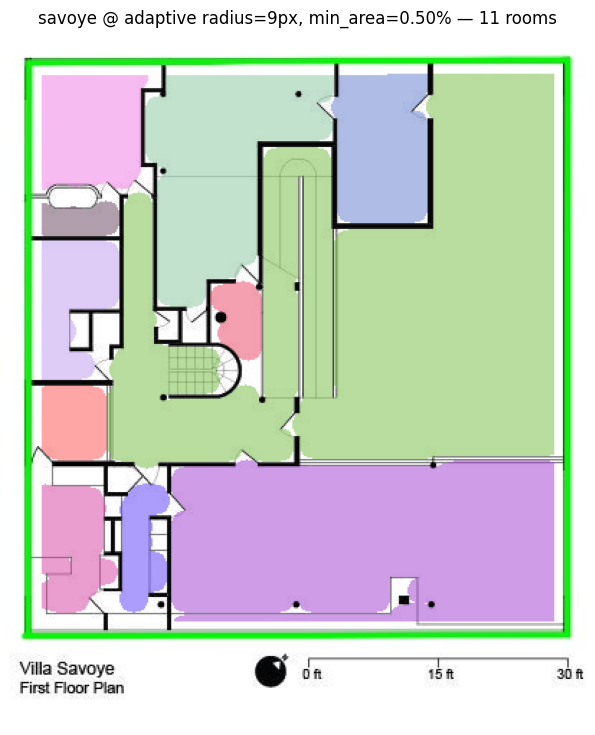

Open Plan: True
Final Score (Out of 100): 100
Breakdown:
  - Passed Area ( > 15% ): True
  - Passed Density ( < 20% ): True
  - Passed Shape ( Convexity < 0.85 ): True
Raw Metrics:
  - Blob Ratio: 0.34
  - Internal Wall Density: 0.000
  - Convexity: 0.72

--- Processing canoas ---


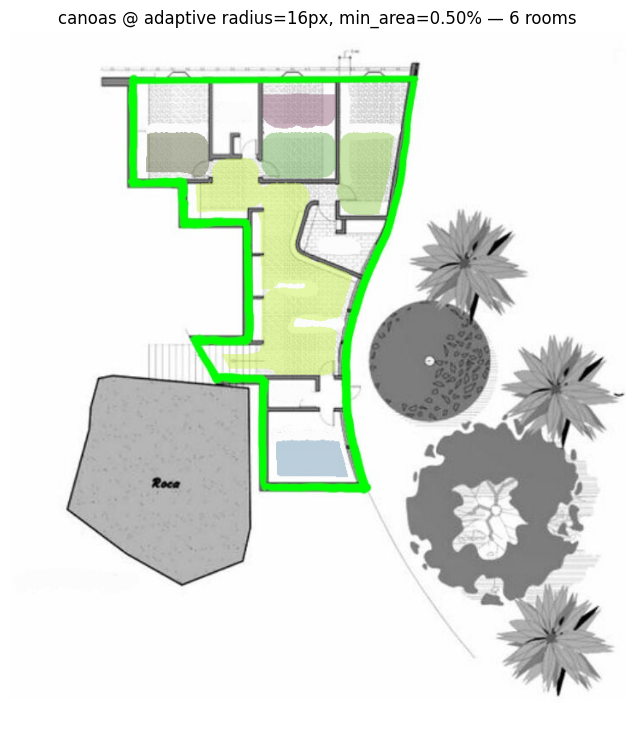

Open Plan: True
Final Score (Out of 100): 100
Breakdown:
  - Passed Area ( > 15% ): True
  - Passed Density ( < 20% ): True
  - Passed Shape ( Convexity < 0.85 ): True
Raw Metrics:
  - Blob Ratio: 0.21
  - Internal Wall Density: 0.000
  - Convexity: 0.58

--- Processing freyhouse2 ---


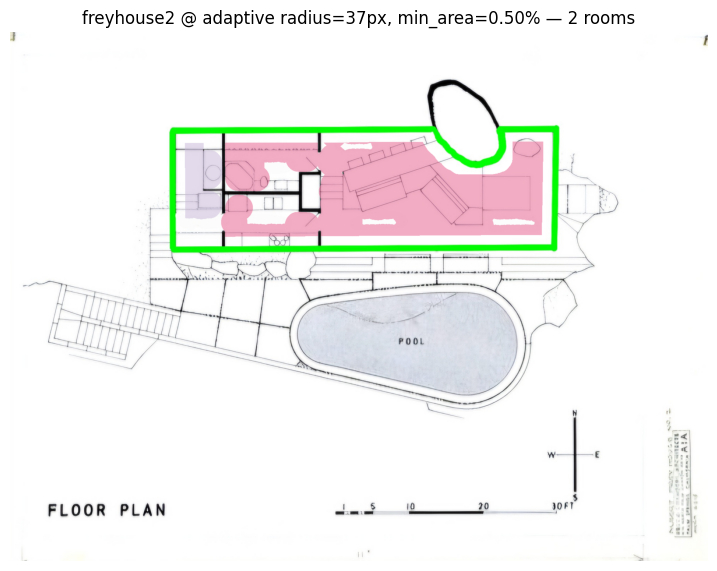

Open Plan: True
Final Score (Out of 100): 100
Breakdown:
  - Passed Area ( > 15% ): True
  - Passed Density ( < 20% ): True
  - Passed Shape ( Convexity < 0.85 ): True
Raw Metrics:
  - Blob Ratio: 0.50
  - Internal Wall Density: 0.000
  - Convexity: 0.78

--- Processing kaufmann ---


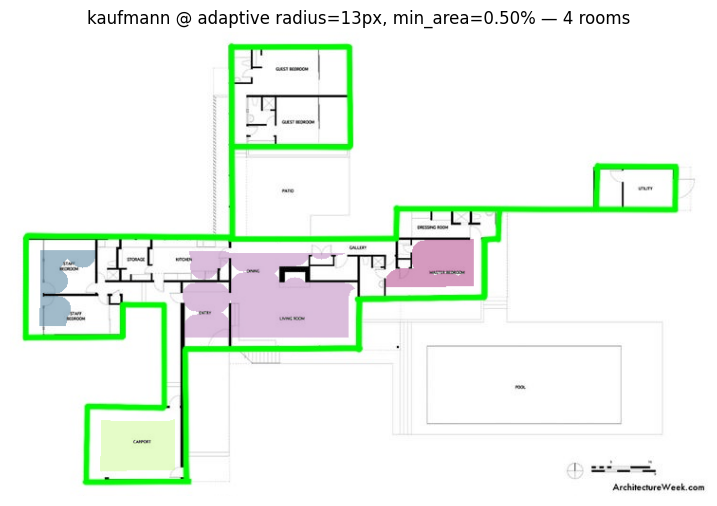

Open Plan: True
Final Score (Out of 100): 70
Breakdown:
  - Passed Area ( > 15% ): False
  - Passed Density ( < 20% ): True
  - Passed Shape ( Convexity < 0.85 ): True
Raw Metrics:
  - Blob Ratio: 0.15
  - Internal Wall Density: 0.000
  - Convexity: 0.82

--- Processing rotonda ---


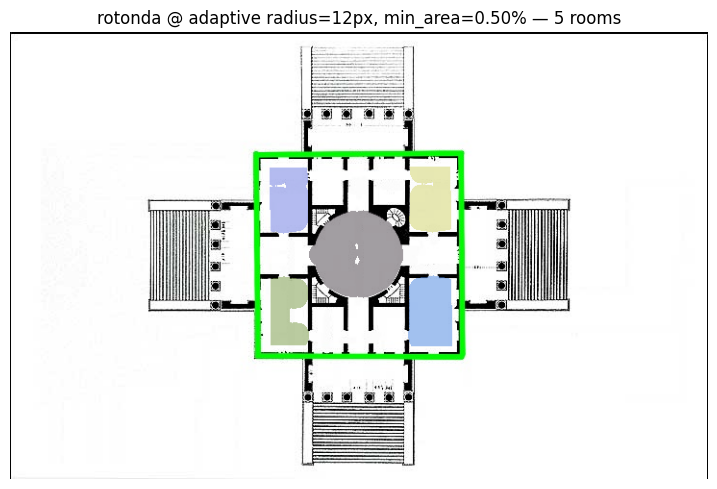

Open Plan: False
Final Score (Out of 100): 30
Breakdown:
  - Passed Area ( > 15% ): False
  - Passed Density ( < 20% ): True
  - Passed Shape ( Convexity < 0.85 ): False
Raw Metrics:
  - Blob Ratio: 0.14
  - Internal Wall Density: 0.000
  - Convexity: 1.00


In [19]:
building_ids = ["savoye", "canoas", "freyhouse2", "kaufmann", "rotonda"]
open_plan_results = {}

for bid in building_ids:
    print(f"\n--- Processing {bid} ---")
    # Keep V9 for the segmentation (coloring), it was the best one yet.
    overlay, room_blobs, space_mask, labels, inside_mask, closed_interior_walls = adaptive_room_flood_v6(bid)

    # Analyze with the new V11 logical system
    result = analyze_open_plan_metrics_v11(room_blobs, inside_mask, closed_interior_walls)
    open_plan_results[bid] = result

    print(f"Open Plan: {result['is_open_plan']}")
    print(f"Final Score (Out of 100): {result['final_score']}")
    print("Breakdown:")
    print(f"  - Passed Area ( > 15% ): {result['breakdown']['area_score'] > 0}")
    print(f"  - Passed Density ( < 20% ): {result['breakdown']['density_score'] > 0}")
    print(f"  - Passed Shape ( Convexity < 0.85 ): {result['breakdown']['shape_score'] > 0}")
    print("Raw Metrics:")
    print(f"  - Blob Ratio: {result['raw_metrics']['blob_ratio']:.2f}")
    print(f"  - Internal Wall Density: {result['raw_metrics']['largest_room_wall_density']:.3f}")
    print(f"  - Convexity: {result['raw_metrics']['convexity']:.2f}")


## 6 · Free facade (glass extent method)

--- FREE FACADE DETECTION (DRAWN EXTENT RATIO) ---

Processing savoye...


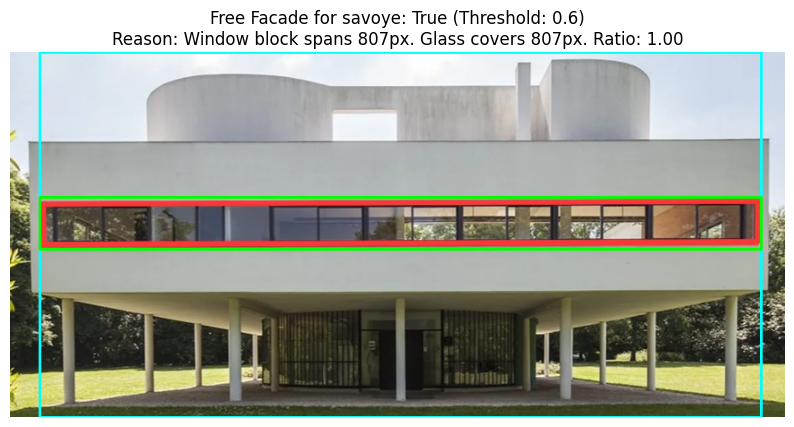

  -> Free Facade: True
  -> Reason: Window block spans 807px. Glass covers 807px. Ratio: 1.00

Processing canoas...


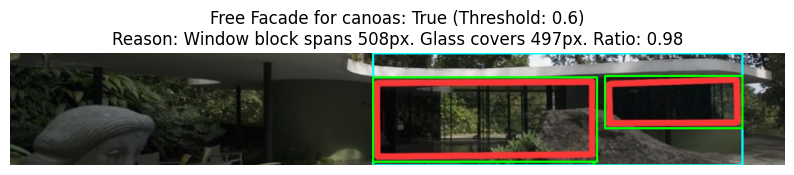

  -> Free Facade: True
  -> Reason: Window block spans 508px. Glass covers 497px. Ratio: 0.98

Processing freyhouse2...


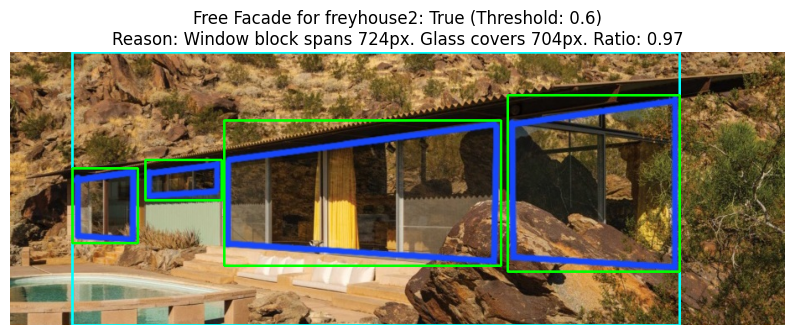

  -> Free Facade: True
  -> Reason: Window block spans 724px. Glass covers 704px. Ratio: 0.97

Processing kaufmann...


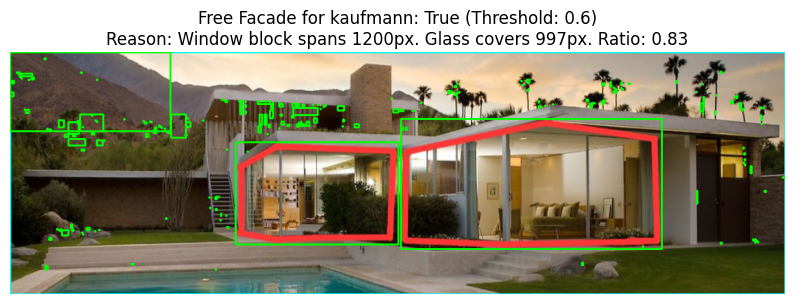

  -> Free Facade: True
  -> Reason: Window block spans 1200px. Glass covers 997px. Ratio: 0.83


In [20]:
# --- COMPLETE FREE FACADE ANALYSIS (GLASS EXTENT METHOD) ---

def find_marked_path(image_id, folder="images"):
    for ext in ["jpg", "jpeg", "png", "JPG", "JPEG", "PNG"]:
        path = f"{PROJECT_DIR}/{folder}/{image_id}_marked.{ext}"
        if os.path.exists(path):
            return path
    return None

def analyze_free_facade_horizontal_only(image_id, pen_color="red", extent_threshold=0.60):
    path = find_marked_path(image_id)
    if path is None:
        return {'is_free_facade': False, 'reason': 'Marked image not found'}

    img = cv2.imread(path)
    if img is None:
        return {'is_free_facade': False, 'reason': 'Failed to load image'}

    h, w = img.shape[:2]
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # 1. Extract the drawn window mask
    if pen_color == "red":
        lower1, upper1 = np.array([0, 70, 50]), np.array([10, 255, 255])
        lower2, upper2 = np.array([170, 70, 50]), np.array([180, 255, 255])
        mask = cv2.inRange(hsv, lower1, upper1) + cv2.inRange(hsv, lower2, upper2)
    elif pen_color == "blue":
        lower, upper = np.array([100, 70, 50]), np.array([130, 255, 255])
        mask = cv2.inRange(hsv, lower, upper)
    else:
        return {'is_free_facade': False, 'reason': 'Unsupported pen color'}

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return {'is_free_facade': False, 'reason': 'No window contours found'}

    bboxes = [cv2.boundingRect(c) for c in contours]

    # --- THE NEW ROBUST METHOD: DRAWN EXTENT RATIO ---
    # 1. Find the horizontal spread of the total window group
    min_x = min(b[0] for b in bboxes)
    max_x = max(b[0] + b[2] for b in bboxes)
    drawn_extent_width = max_x - min_x

    # 2. Count the actual X-coordinates covered by glass within that group
    vertical_projection = np.sum(mask, axis=0)
    glass_pixel_columns = np.sum(vertical_projection > 0)

    # 3. Calculate the Glass Extent Ratio
    if drawn_extent_width == 0:
        glass_extent_ratio = 0
    else:
        glass_extent_ratio = glass_pixel_columns / drawn_extent_width

    # --- DECISION LOGIC ---
    # Is glass covering > 60% of the total horizontal span of the window group?
    is_free = glass_extent_ratio > extent_threshold
    reason = f"Window block spans {drawn_extent_width}px. Glass covers {glass_pixel_columns}px. Ratio: {glass_extent_ratio:.2f}"

    # --- VISUALIZATION ---
    vis_img = img.copy()
    # Draw the extents of the window group in Cyan
    cv2.rectangle(vis_img, (min_x, 0), (max_x, h), (255, 255, 0), 2)
    # Draw individual window bounding boxes in Green
    for cnt in contours:
        x, y, w_box, h_box = cv2.boundingRect(cnt)
        cv2.rectangle(vis_img, (x, y), (x + w_box, y + h_box), (0, 255, 0), 2)

    plt.figure(figsize=(10, 5))
    plt.imshow(cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Free Facade for {image_id}: {is_free} (Threshold: {extent_threshold})\nReason: {reason}")
    plt.axis('off')
    plt.show()

    return {'is_free_facade': is_free, 'reason': reason}

# --- FUNCTION CALL LOOP ---

print("--- FREE FACADE DETECTION (DRAWN EXTENT RATIO) ---")
for bid in image_ids:
    print(f"\nProcessing {bid}...")
    result = analyze_free_facade_horizontal_only(bid, pen_color=pen_colors[bid], extent_threshold=0.60)
    print(f"  -> Free Facade: {result['is_free_facade']}")
    print(f"  -> Reason: {result['reason']}")


## 7 · Flat-roof classifier (CLIP + geometric veto)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (2 outputs left out)

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

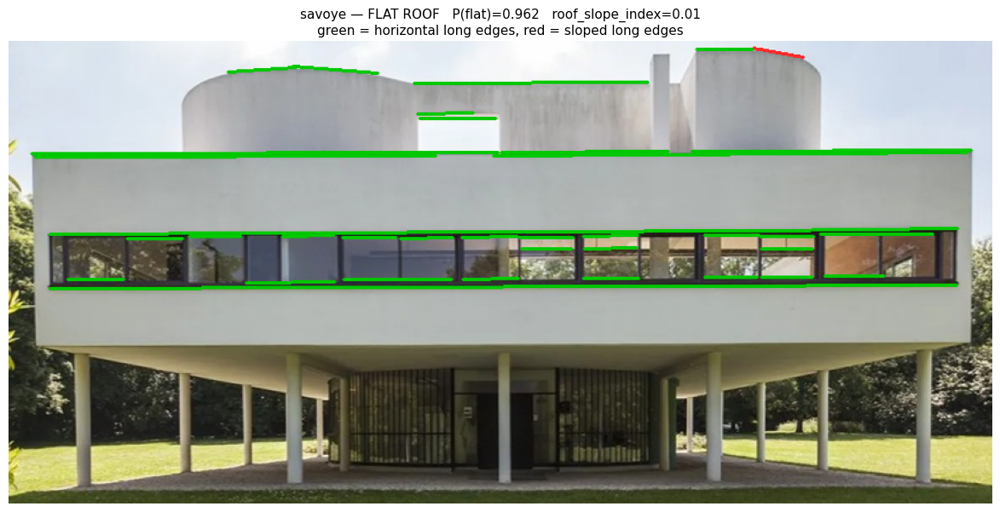

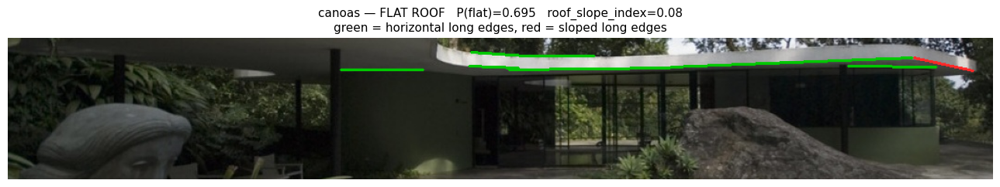

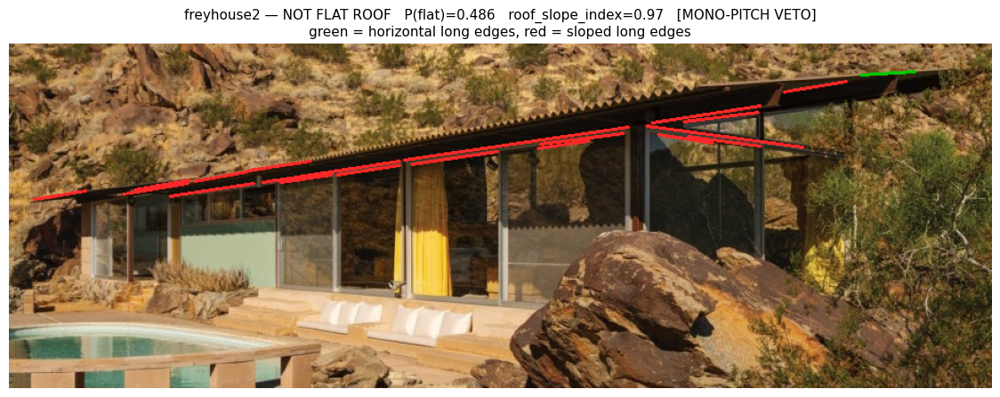

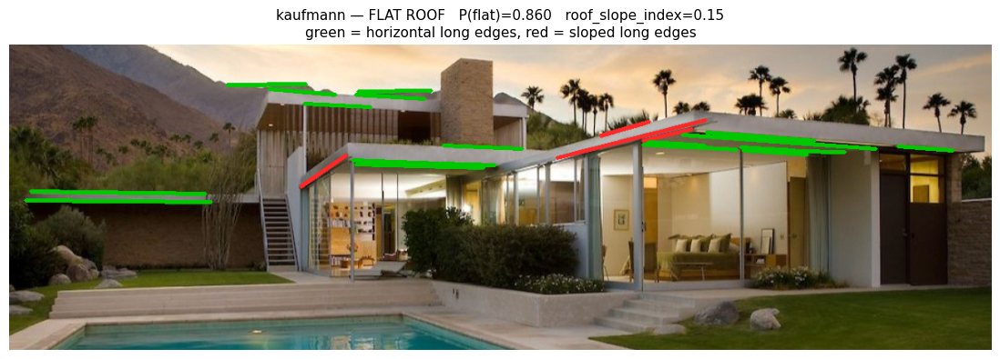

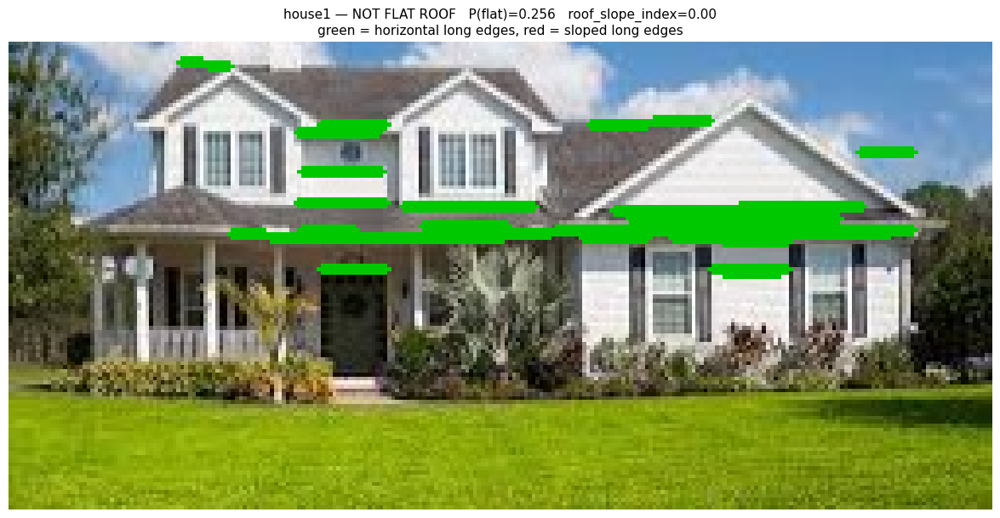


        id  is_flat_roof  expected  correct   p_flat   margin  roof_slope_index  mono_pitch_veto decided_by
    savoye          True      True     True 0.961879 0.923758          0.009285            False       CLIP
    canoas          True      True     True 0.694659 0.389318          0.075410            False       CLIP
freyhouse2         False     False     True 0.486400 0.027200          0.967339             True       CLIP
  kaufmann          True      True     True 0.860247 0.720495          0.150355            False       CLIP
    house1         False     False     True 0.256254 0.487493          0.000000            False       CLIP

ACCURACY: 5/5
  warning  freyhouse2: low CLIP margin (0.03) — verify visually.


In [21]:
# =============================================================================
#  FLAT-ROOF CLASSIFIER — single Colab cell (per-image version)
#  Replaces detect_flat_roof_eave_gap().  Validated 12/13 on 13 exterior photos.
#
#  Decision = CLIP zero-shot (semantic), because roof pitch is a 3-D property
#  a single-view silhouette cannot recover.  A geometric "roof slope index"
#  runs alongside as a one-sided veto for mono-pitch/shed roofs.
#
#  Known failure mode: a pitched roof photographed ALONG its slope direction
#  projects to a horizontal line and is unrecoverable from that photo alone.
# =============================================================================

# ----------------------------------------------------------------- config ---
IMAGE_DIR = f"{PROJECT_DIR}/images"
CROP_SUFFIX = "_crop"

BUILDING_IDS = ["savoye", "canoas", "freyhouse2", "kaufmann", "house1"]

GROUND_TRUTH = {                 # used only to VERIFY, never to decide
    "savoye": True, "canoas": True, "kaufmann": True,
    "freyhouse2": False, "house1": False,
}

CLIP_MODEL = "openai/clip-vit-base-patch32"   # the validated model
SLOPE_VETO = 0.60            # roof_slope_index above this => force NOT FLAT
MARGIN_WARN = 0.15           # flag low-confidence CLIP decisions
RESIZE_WIDTH = 1000
MANUAL_OVERRIDES = {}        # auditable escape hatch, e.g. {"freyhouse2": False}

# ------------------------------------------------------------------ paths ---
def find_crop_path(image_id, folder=None, suffix=None):
    folder = IMAGE_DIR if folder is None else folder
    suffix = CROP_SUFFIX if suffix is None else suffix
    for ext in ("jpg", "jpeg", "png", "JPG", "JPEG", "PNG", "webp"):
        p = f"{folder}/{image_id}{suffix}.{ext}"
        if os.path.exists(p):
            return p
    if os.path.isdir(folder):                      # tolerate odd extensions
        for f in sorted(os.listdir(folder)):
            if f.lower().startswith(f"{image_id}{suffix}".lower()):
                return f"{folder}/{f}"
    raise FileNotFoundError(f"No crop found for '{image_id}' in {folder}")

def load_rgb(image_id):
    path = image_id if os.path.isfile(image_id) else find_crop_path(image_id)
    bgr = cv2.imread(path)
    if bgr is None:
        raise IOError(f"cv2 could not decode {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), path

# ------------------------------------------------- geometric roof evidence ---
def _segments(gray, resize_width=RESIZE_WIDTH):
    """Long straight segments as (length, angle_deg, y_mid_frac, endpoints)."""
    h, w = gray.shape[:2]
    g = cv2.resize(gray, (resize_width, max(1, int(h * resize_width / w))),
                   interpolation=cv2.INTER_AREA)
    H, W = g.shape
    raw = None
    try:                                    # LSD is missing in OpenCV 4.5–4.7
        det = cv2.createLineSegmentDetector(cv2.LSD_REFINE_STD).detect(g)[0]
        if det is not None:
            raw = det.reshape(-1, 4)
    except Exception:
        raw = None
    if raw is None:                                    # HoughLinesP fallback
        edges = cv2.Canny(cv2.GaussianBlur(g, (5, 5), 0), 50, 150)
        det = cv2.HoughLinesP(edges, 1, np.pi / 360, threshold=60,
                              minLineLength=int(0.05 * W), maxLineGap=6)
        raw = det.reshape(-1, 4) if det is not None else np.zeros((0, 4))

    out = []
    for x1, y1, x2, y2 in raw:
        length = float(np.hypot(x2 - x1, y2 - y1))
        ang = float((np.degrees(np.arctan2(y2 - y1, x2 - x1)) + 90) % 180 - 90)
        out.append((length, ang, float((y1 + y2) / 2 / H),
                    (float(x1) / W, float(y1) / H, float(x2) / W, float(y2) / H)))
    return out

def roof_slope_index(rgb, band=0.55, min_len_frac=0.05,
                     horiz_tol=5.0, slope_tol=6.0, max_ang=60.0):
    """Sloped edge length / total long-edge length, in the upper band.

    One-sided by design: a HIGH score proves a sloping roof; a LOW score proves
    nothing, because a gable seen head-on shows horizontal eaves and short rakes.
    """
    segs = _segments(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY))
    horiz_len = slope_len = 0.0
    kept = []
    for length, ang, ymid, pts in segs:
        if length < min_len_frac * RESIZE_WIDTH or abs(ang) > max_ang or ymid > band:
            continue
        if abs(ang) <= horiz_tol:
            horiz_len += length
            kept.append(("h", pts))
        elif abs(ang) >= slope_tol:
            slope_len += length
            kept.append(("s", pts))
    total = horiz_len + slope_len
    return {"roof_slope_index": slope_len / total if total else 0.0,
            "segments": kept}

# --------------------------------------------------- semantic decision -------
FLAT_PROMPTS = [
    "a photo of a building with a flat roof",
    "a modernist house with a flat roof and a roof terrace",
    "a house whose roof is a horizontal concrete slab",
    "a flat-roofed modern villa",
    "a building with a flat roofline and a parapet",
    "modern architecture with a horizontal flat roof",
    "a house with a flat roof deck on top",
    "a rectilinear white house with a completely flat roof",
    "a glass pavilion with a flat overhanging roof slab",
]
NOT_FLAT_PROMPTS = [
    "a photo of a building with a pitched roof",
    "a house with a gabled roof",
    "a suburban house with a sloping shingle roof",
    "a house with a triangular gable and dormers",
    "a building with a shed roof sloping to one side",
    "a house with a single-pitch sloping metal roof",
    "a house with a hip roof",
    "a house with a steeply sloping roof",
    "a cabin with a slanted roof that slopes downward",
]

_clip = {}

def _get_clip():
    if not _clip:
        _clip["m"] = CLIPModel.from_pretrained(CLIP_MODEL).eval()
        _clip["p"] = CLIPProcessor.from_pretrained(CLIP_MODEL)
    return _clip["m"], _clip["p"]

def _square_views(rgb, band=None, min_views=3, overlap=0.5):
    """Square windows + a letterbox view.

    Necessary because CLIPProcessor resizes the short edge then CENTER-CROPS:
    on canoas_crop (1066x154, ~7:1) that would discard ~85% of the building.
    """
    img = rgb if band is None else rgb[: max(8, int(band * rgb.shape[0]))]
    h, w = img.shape[:2]
    side = max(h, w)
    pad = np.full((side, side, 3), 255, np.uint8)
    pad[(side - h) // 2:(side - h) // 2 + h, (side - w) // 2:(side - w) // 2 + w] = img
    views = [pad]

    if w >= h:
        s, stride = h, max(1, int(h * (1 - overlap)))
        xs = list(range(0, max(1, w - s + 1), stride)) or [0]
        if len(xs) < min_views:
            xs = np.linspace(0, max(0, w - s), min_views).astype(int).tolist()
        views += [img[:, x:x + s] for x in xs]
    else:
        s, stride = w, max(1, int(w * (1 - overlap)))
        views += [img[y:y + s, :] for y in range(0, max(1, h - s + 1), stride)]
    return [v for v in views if v.shape[0] > 8 and v.shape[1] > 8]

def clip_flat_roof_score(rgb):
    model, proc = _get_clip()
    views = _square_views(rgb) + _square_views(rgb, band=0.60)
    prompts = FLAT_PROMPTS + NOT_FLAT_PROMPTS
    n_flat = len(FLAT_PROMPTS)
    with torch.no_grad():
        inp = proc(text=prompts, images=[Image.fromarray(v) for v in views],
                   return_tensors="pt", padding=True, truncation=True)
        # logits_per_image is the one CLIP output whose meaning and shape are
        # stable across transformers 4.x/5.x: logit_scale * cos(image, text).
        # (In transformers 5.x, get_image_features returns an output object,
        #  not a tensor — using it here silently breaks.)
        sim = model(**inp).logits_per_image          # [n_views, n_prompts]
        # mean per class BEFORE softmax, so unequal prompt counts cannot bias it
        s_flat, s_not = sim[:, :n_flat].mean(), sim[:, n_flat:].mean()
        p = torch.softmax(torch.stack([s_flat, s_not]), 0)[0]
    return float(p)

# ------------------------------------------------------------- classifier ---
def detect_flat_roof(image_id, show=True):
    rgb, path = load_rgb(image_id)
    geo = roof_slope_index(rgb)
    p = clip_flat_roof_score(rgb)

    veto = geo["roof_slope_index"] > SLOPE_VETO
    is_flat = (p > 0.5) and not veto
    decided_by = "CLIP+veto" if (veto and p > 0.5) else "CLIP"
    if image_id in MANUAL_OVERRIDES:
        is_flat, decided_by = MANUAL_OVERRIDES[image_id], "MANUAL"

    res = {"id": image_id, "is_flat_roof": bool(is_flat), "p_flat": p,
           "margin": abs(p - 0.5) * 2, "roof_slope_index": geo["roof_slope_index"],
           "mono_pitch_veto": bool(veto), "decided_by": decided_by,
           "low_confidence": abs(p - 0.5) * 2 < MARGIN_WARN, "path": path}
    if show:
        vis, (h, w) = rgb.copy(), rgb.shape[:2]
        for kind, (x1, y1, x2, y2) in geo["segments"]:
            cv2.line(vis, (int(x1 * w), int(y1 * h)), (int(x2 * w), int(y2 * h)),
                     (0, 200, 0) if kind == "h" else (255, 40, 40), max(2, w // 400))
        plt.figure(figsize=(13, max(3, 13 * h / w)))
        plt.imshow(vis); plt.axis("off")
        plt.title(f"{image_id} — {'FLAT ROOF' if is_flat else 'NOT FLAT ROOF'}   "
                  f"P(flat)={p:.3f}   roof_slope_index={geo['roof_slope_index']:.2f}"
                  f"{'   [MONO-PITCH VETO]' if veto else ''}\n"
                  "green = horizontal long edges, red = sloped long edges", fontsize=11)
        plt.tight_layout(); plt.show()
    return res

def run_all(building_ids=None, show=True):
    df = pd.DataFrame([detect_flat_roof(b, show=show)
                       for b in (building_ids or BUILDING_IDS)])
    df["expected"] = df["id"].map(GROUND_TRUTH)
    df["correct"] = df["is_flat_roof"] == df["expected"]
    cols = ["id", "is_flat_roof", "expected", "correct", "p_flat", "margin",
            "roof_slope_index", "mono_pitch_veto", "decided_by"]
    print("\n" + "=" * 92)
    print(df[cols].to_string(index=False))
    print(f"\nACCURACY: {int(df['correct'].sum())}/{len(df)}")
    for _, r in df[df["low_confidence"]].iterrows():
        print(f"  warning  {r['id']}: low CLIP margin ({r['margin']:.2f}) — verify visually.")
    print("=" * 92)
    os.makedirs(f"{PROJECT_DIR}/data", exist_ok=True)
    df.to_csv(f"{PROJECT_DIR}/data/roof_classification.csv", index=False)
    return df

roof_df = run_all()
